In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Atur tampilan agar grafik rapi
sns.set_theme(style="whitegrid")
print("Library berhasil di-import!")

# Read CSV dengan delimiter koma
df_main = pd.read_csv('data/sensor_data_main.csv')

# Read CSV dengan delimiter titik-koma
df_semi = pd.read_csv('data/sensor_data_semicolon.csv', sep=';')

# Read Excel Multi-sheet
excel_file = pd.ExcelFile('data/sensor_data_monthly.xlsx')
df_jan = excel_file.parse('Jan2026')
df_feb = excel_file.parse('Feb2026')

# Gabungkan data awal menjadi satu DataFrame
df_raw = pd.concat([df_main, df_semi, df_jan, df_feb], ignore_index=True)

print(f"Total baris data mentah: {len(df_raw)}")
df_raw.head()

Library berhasil di-import!
Total baris data mentah: 400


,timestamp,sensor_id,location,temperature_celsius,humidity_percent,pressure_hpa,air_quality_aqi,status
0,2026-01-01 00:00:00,S101,Lab Utama,25.618102,41.257167,1012.840633,128,ACTIVE
1,2026-01-01 01:00:00,S101,Lab Utama,34.260715,65.456416,1001.682799,135,ACTIVE
2,2026-01-01 02:00:00,S101,Lab Utama,30.979909,52.574239,1003.232574,113,ACTIVE
3,2026-01-01 03:00:00,S101,Lab Utama,28.979877,60.342828,1017.971084,66,ACTIVE
4,2026-01-01 04:00:00,S101,Lab Utama,22.340280,76.302659,1012.128581,118,ACTIVE


In [22]:
df_clean = df_raw.copy()

# Merapikan spasi liar dan menyamakan format huruf
df_clean['location'] = df_clean['location'].str.strip().str.title()
df_clean['status'] = df_clean['status'].str.strip().str.upper()

print("Lokasi setelah dibersihkan:", df_clean['location'].unique())
print("Status setelah dibersihkan:", df_clean['status'].unique())

Lokasi setelah dibersihkan: <ArrowStringArray>
['Lab Utama', 'Ruang Server']
Length: 2, dtype: str
Status setelah dibersihkan: <ArrowStringArray>
['ACTIVE']
Length: 1, dtype: str


In [23]:
# Mengubah angka suhu ngawur (>50 C) menjadi NaN
df_clean.loc[df_clean['temperature_celsius'] > 50, 'temperature_celsius'] = np.nan

# Mengisi data kosong tersebut dengan nilai median suhu
median_temp = df_clean['temperature_celsius'].median()
df_clean['temperature_celsius'] = df_clean['temperature_celsius'].fillna(median_temp)

print("Imputasi selesai! Nilai median suhu:", median_temp)

Imputasi selesai! Nilai median suhu: 24.66473482573493


In [24]:
# Menghitung konversi suhu dari Celsius ke Fahrenheit
df_clean['temperature_fahrenheit'] = (df_clean['temperature_celsius'] * 9/5) + 32

df_clean[['timestamp', 'temperature_celsius', 'temperature_fahrenheit']].head()

,timestamp,temperature_celsius,temperature_fahrenheit
0,2026-01-01 00:00:00,25.618102,78.112583
1,2026-01-01 01:00:00,34.260715,93.669286
2,2026-01-01 02:00:00,30.979909,87.763836
3,2026-01-01 03:00:00,28.979877,84.163779
4,2026-01-01 04:00:00,22.340280,72.212503


In [26]:
import os

# 1. Pastikan kolom timestamp resmi bertipe datetime64
df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'])

# 2. Memastikan data sudah 100% bersih dari nilai kosong
assert df_clean.isnull().sum().sum() == 0, "Masih ada data kosong!"

# 3. Menyimpan data bersih ke berbagai format file
df_clean.to_csv('data/sensor_data_cleaned.csv', index=False)
df_clean.to_parquet('data/sensor_data_cleaned.parquet', index=False)
df_clean.to_json('data/sensor_data_cleaned.json', orient='records')
df_clean.to_excel('data/sensor_data_cleaned.xlsx', index=False)

# 4. Pengecekan ukuran file hasil export
files = ['sensor_data_cleaned.csv', 'sensor_data_cleaned.parquet', 'sensor_data_cleaned.json', 'sensor_data_cleaned.xlsx']
file_info = []

for f in files:
    size_kb = os.path.getsize(os.path.join('data', f)) / 1024
    file_info.append({'Format File': f, 'Ukuran File (KB)': round(size_kb, 2)})

df_sizes = pd.DataFrame(file_info)
display(df_sizes)

C:\Users\Ayu Halimatus S\AppData\Local\Temp\ipykernel_14948\1799940730.py:12: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_clean.to_json('data/sensor_data_cleaned.json', orient='records')


,Format File,Ukuran File (KB)
0,sensor_data_cleaned.csv,46.99
1,sensor_data_cleaned.parquet,17.72
2,sensor_data_cleaned.json,97.40
3,sensor_data_cleaned.xlsx,35.85


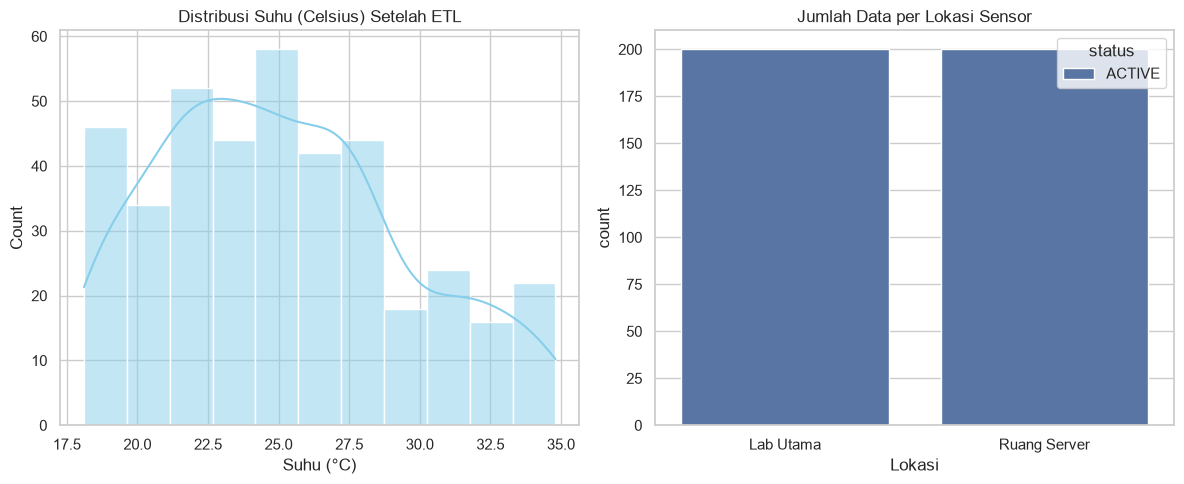

In [27]:
plt.figure(figsize=(12, 5))

# Grafik 1: Distribusi Suhu
plt.subplot(1, 2, 1)
sns.histplot(df_clean['temperature_celsius'], kde=True, color='skyblue')
plt.title('Distribusi Suhu (Celsius) Setelah ETL')
plt.xlabel('Suhu (°C)')

# Grafik 2: Perbandingan Status Sensor
plt.subplot(1, 2, 2)
sns.countplot(data=df_clean, x='location', hue='status')
plt.title('Jumlah Data per Lokasi Sensor')
plt.xlabel('Lokasi')

plt.tight_layout()
plt.show()